# 06f every fine-tuning variant in one table

No training. Steps 4, 6b, 6c, 6d and 6e each fine-tuned the same pretrained body under one change at a time and compared it with a control inside that notebook; this notebook reads all of their result files (`results/metrics/*_seed<k>.json`) and puts every variant in one table, plus the two seed ensembles computed from the saved test scores.

**Rules the table follows.**

| rule | why |
|---|---|
| every variant is compared with a control trained on the same machine with the same code, in units of that control's seed sd | 06b gate G3 showed the same recipe differs by 0.0012 between the T4 and this laptop, more than the sd; a cross-machine gap is a machine effect |
| the control is 06b's H12 last-token arm, except the 06c arms, which use the A_ref retrained inside their own group | 06c changed the tokenizer or the objective, so it retrained its own control |
| the Colab T4 runs of step 4 and the two XGBoost models show the difference only, never sd units | other machine, or other model family: a tree's seed sd says nothing about a transformer's |
| a variant whose files are missing is skipped, not invented | the table is built from what was measured |
| XGBoost gets the same seed ensemble the transformer gets | the ensemble was the one change that raised the transformer's score (06d); the comparison is fair only if the tree gets it too. XGBoost had its hyper-parameter grid in step 5 already, which is the tree's counterpart of the learning-rate sweep |

In [1]:
import os, sys, glob, shutil
try:
    from google.colab import drive, userdata                      # Colab: mount Drive, pull the repo, sync new notebooks to Drive
    drive.mount("/content/drive")
    tok = userdata.get("GH_TOKEN")
    if not os.path.exists("/content/transaction-fm"):
        !git clone -q https://{tok}@github.com/lb603487485/transaction-fm.git /content/transaction-fm
    else:
        !cd /content/transaction-fm && git pull -q
    %pip install -q datasets xgboost
    %cd /content/transaction-fm
except ImportError:                                               # laptop: this notebook is the repo copy; data under $TFM_ROOT
    here = os.getcwd()
    while not os.path.isdir(os.path.join(here, "src", "tfm")):
        assert here != os.path.dirname(here), "run this notebook from inside the transaction-fm repo"
        here = os.path.dirname(here)
    %cd {here}
sys.path.insert(0, os.path.abspath("src"))
from tfm.runtime import root, describe, on_colab
ROOT = root()
os.makedirs(f"{ROOT}/notebooks", exist_ok=True)
if on_colab():
    for f in glob.glob("notebooks/*.ipynb"):                      # new notebooks from the repo appear in Drive
        dst = f"{ROOT}/notebooks/{os.path.basename(f)}"
        if not os.path.exists(dst):
            shutil.copy(f, dst); print("new notebook in Drive:", os.path.basename(f))
import tfm
print("tfm ok |", describe(), "| ROOT =", ROOT)

/Users/evolin1/Desktop/AICoding/MLProject/transaction-fm


tfm ok | {'where': 'laptop', 'gpu': None, 'device': 'cpu', 'accelerator': 'mps', 'fp16': False, 'machine': 'Darwin arm64 12 cores'} | ROOT = /Users/evolin1/Desktop/AICoding/MLProject/transaction-fm


## Stage 6f-0: the table from the result files, the two ensembles from the saved test scores

In [2]:
import json, os, glob, numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)
from tfm.compare import VARIANTS, REF, finetune_table, ensemble_row
from tfm.runtime import describe

RES = f"{ROOT}/results"
RD = "results/metrics" if glob.glob(f"results/metrics/{REF}_seed*.json") else RES      # the repo copies, or Drive's results/
rows = finetune_table(RD)
ref = next(r for r in rows if r["control"] == REF and r["variant"].startswith("reference"))
print(f"{len(rows)} variants found of {len(VARIANTS)} known | reference {ref['pr_auc']:.4f} +- {ref['sd']:.4f} on {ref['machine']}")

df = pd.read_parquet(f"{ROOT}/data/processed/transactions.parquet")
te = (df["split"] == "test").to_numpy(); yt, ct = df["is_fraud"].to_numpy()[te], df["card_id"].to_numpy()[te]
def seed_scores(pat):
    out = []
    for k in (0, 1, 2):
        p = f"{ROOT}/{pat.format(k=k)}/test_scores.npy"
        if os.path.exists(p):
            s = np.load(p); assert len(s) == len(yt), (p, len(s), len(yt)); out.append(s)
    return out
for label, pat in [("seed ensemble: mean of the three reference seeds (06b scores)", "ablate/H12_last/seed{k}"),
                   ("seed ensemble: mean of the three XGBoost seeds (05 scores)", "baseline/full/seed{k}")]:
    sc = seed_scores(pat)
    if len(sc) == 3:
        r = ensemble_row(label, sc, yt, ct, ref["pr_auc"], ref["sd"])
        if "XGBoost" in label: r["in_control_sd"], r["note"] = None, "other model family: difference only"
        rows.append(r)
    else:
        print("ensemble skipped, scores missing:", label, len(sc))

tab = pd.DataFrame(rows)
show = tab[["variant", "n_seeds", "trainable_params", "pr_auc", "sd", "recall_at_alert", "diff", "in_control_sd", "note"]]
display(show.style.format({"pr_auc": "{:.4f}", "sd": "{:.4f}", "recall_at_alert": "{:.4f}", "diff": "{:+.4f}", "in_control_sd": "{:+.1f}", "trainable_params": "{:,.0f}"}, na_rep="").hide(axis="index"))

23 variants found of 23 known | reference 0.9845 +- 0.0021 on Darwin arm64 12 cores / mps


variant,n_seeds,trainable_params,pr_auc,sd,recall_at_alert,diff,in_control_sd,note
"reference: pretrained body, full fine-tuning, H12, last token, lr 5e-5, keep 0.05 (06b)",3,,0.9845,0.0021,0.9871,+0.0000,+0.0,
same configuration trained on the Colab T4 (04),3,,0.9857,0.0003,0.9888,+0.0012,,other machine: difference only
"random body instead of pretrained, Colab T4 (04)",3,,0.9415,0.0009,0.9497,-0.0429,,other machine: difference only
history 0 instead of 12 (06b),3,,0.7405,0.0055,0.7672,-0.2440,-113.6,
history 5 instead of 12 (06b),3,,0.9788,0.0019,0.9837,-0.0057,-2.7,
history 32 instead of 12 (06b),3,,0.9843,0.0008,0.9871,-0.0001,-0.1,
mean pooling instead of last token (06b),3,,0.8973,0.0028,0.9052,-0.0872,-40.6,
"learning rate 1e-5, one seed (06d)",1,"11,062,656",0.9785,,0.9828,-0.0060,-2.8,
"learning rate 2e-5, one seed (06d)",1,"11,062,656",0.9836,,0.9855,-0.0008,-0.4,
"learning rate 1e-4, one seed (06d)",1,"11,062,656",0.9856,,0.9869,+0.0012,+0.5,


## Stage 6f-1: the same table as a figure, and the file

Three rows are left out of the figure because they would flatten the axis: history 0 (0.74), the random-body probe (0.43) and current-only XGBoost (0.78). They are in the table and the json.

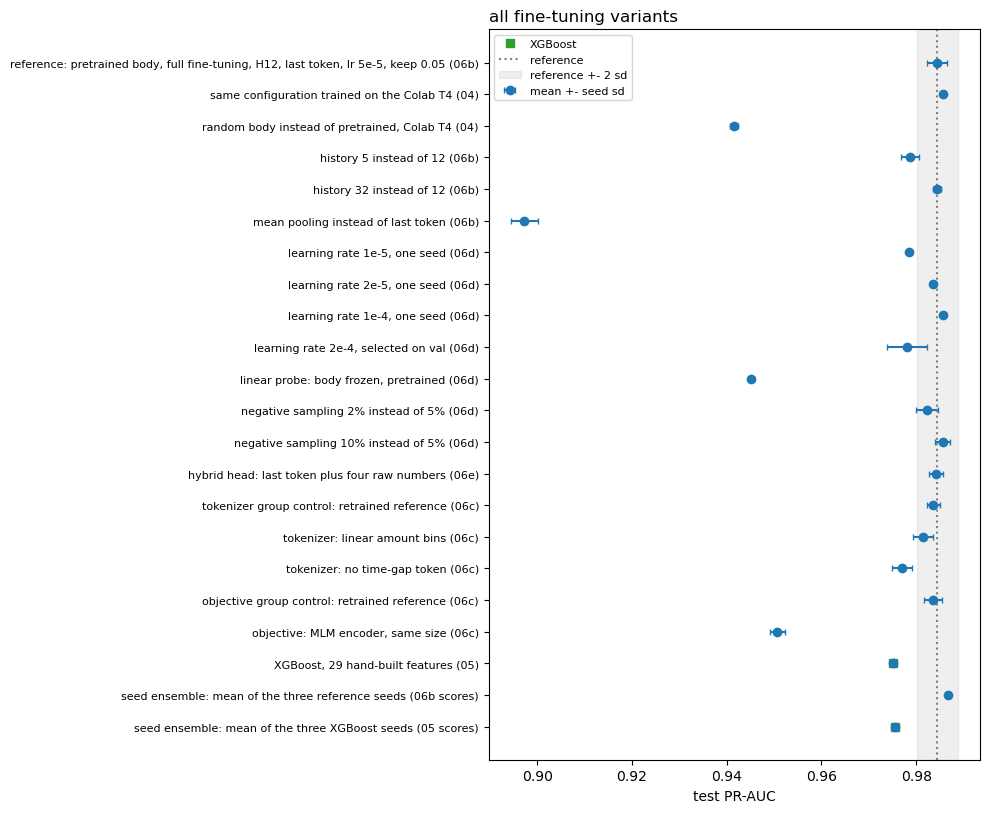

saved 06f_compare_finetunes.json with 25 rows


In [3]:
import matplotlib.pyplot as plt
plot = tab[~tab["variant"].str.startswith("history 0") & ~tab["variant"].str.contains("body frozen, random") & ~tab["variant"].str.contains("current transaction only")]   # the three far-left rows would flatten the axis
plot = plot.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.32 * len(plot) + 1.2))
y = np.arange(len(plot))
ax.errorbar(plot["pr_auc"], y, xerr=plot["sd"].fillna(0), fmt="o", color="tab:blue", ecolor="tab:blue", capsize=2, label="mean +- seed sd")
xg = plot["variant"].str.contains("XGBoost")
ax.plot(plot["pr_auc"][xg], y[xg.to_numpy()], "s", color="tab:green", label="XGBoost")
ax.axvline(ref["pr_auc"], color="grey", ls=":", label="reference")
ax.axvspan(ref["pr_auc"] - 2 * ref["sd"], ref["pr_auc"] + 2 * ref["sd"], color="grey", alpha=0.12, label="reference +- 2 sd")
ax.set_yticks(y); ax.set_yticklabels(plot["variant"], fontsize=8); ax.set_xlabel("test PR-AUC"); ax.set_title("all fine-tuning variants", loc="left"); ax.legend(loc="upper left", fontsize=8); fig.tight_layout(); fig.savefig(f"{RES}/06f_compare.png", dpi=120); plt.show()

out = {"reference": ref, "rows": rows, "n_variants_known": len(VARIANTS), "runtime": describe()}
json.dump(out, open(f"{RES}/06f_compare_finetunes.json", "w"), indent=1, default=float)
print("saved 06f_compare_finetunes.json with", len(rows), "rows")

## What to read off the table

- Rows at or inside the grey band are ties with the reference; outside it, the change mattered. Single-seed learning-rate rows show a trend only.
- The two ensemble rows answer the fairness question: if averaging seeds lifts the transformer and the tree by the same amount, the gap between them is unchanged; if it lifts only one, the headline comparison in the report must use both ensembles or neither.
- The T4 and XGBoost rows carry a difference but no sd units on purpose; see the rules above.

## Push results and this notebook back to GitHub

In [4]:
import shutil, glob, os, json
os.makedirs("results/metrics", exist_ok=True); os.makedirs("results/figures", exist_ok=True)
for f in glob.glob(f"{ROOT}/results/*.json"):
    shutil.copy(f, "results/metrics/")
for f in glob.glob(f"{ROOT}/results/*.png"):
    shutil.copy(f, "results/figures/")
if on_colab():
    def same_code(a, b):   # a Drive notebook may be copied back only if its code cells equal the repo version
        cells = lambda p: ["".join(c["source"]) for c in json.load(open(p))["cells"] if c["cell_type"] == "code"]
        return cells(a) == cells(b)
    for f in glob.glob(f"{ROOT}/notebooks/*.ipynb"):   # outputs are kept so GitHub shows them
        repo = f"notebooks/{os.path.basename(f)}"
        if not os.path.exists(repo) or same_code(f, repo):
            shutil.copy(f, repo)
        else:
            print("STALE, not copied:", os.path.basename(f), "-> delete it from Drive and rerun the setup cell")
    !git config user.email "linboyy@hotmail.com" && git config user.name "Bo Lin"
    !git add results notebooks && git commit -q -m "results and notebooks from Colab" && git pull --rebase -q && git push -q   # the other 06c group may have pushed meanwhile; its files are disjoint
    !git log --oneline | head -1
else:
    print("laptop: results copied into results/; this notebook file already is the repo copy; commit from the terminal")
    !git status --short results notebooks

laptop: results copied into results/; this notebook file already is the repo copy; commit from the terminal
 M notebooks/README.md
?? notebooks/06f_compare_finetunes.ipynb
?? results/figures/06f_compare.png
?? results/metrics/06f_compare_finetunes.json


In [5]:
if on_colab():
    drive.flush_and_unmount()